# Support Vector Machines and Kernels

![SVM.png](../asets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split

from sklearnex import patch_sklearn
patch_sklearn()

%matplotlib inline
sns.set_style('whitegrid')
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)
print(data.shape)
print(data.dtypes.value_counts().to_dict())
print(data.color.value_counts().to_dict())

y = (data['color'] == 'red').astype(int)
data.head()

(6497, 13)
{dtype('float64'): 11, dtype('int64'): 1, <StringDtype(storage='python', na_value=nan)>: 1}
{'white': 4898, 'red': 1599}


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


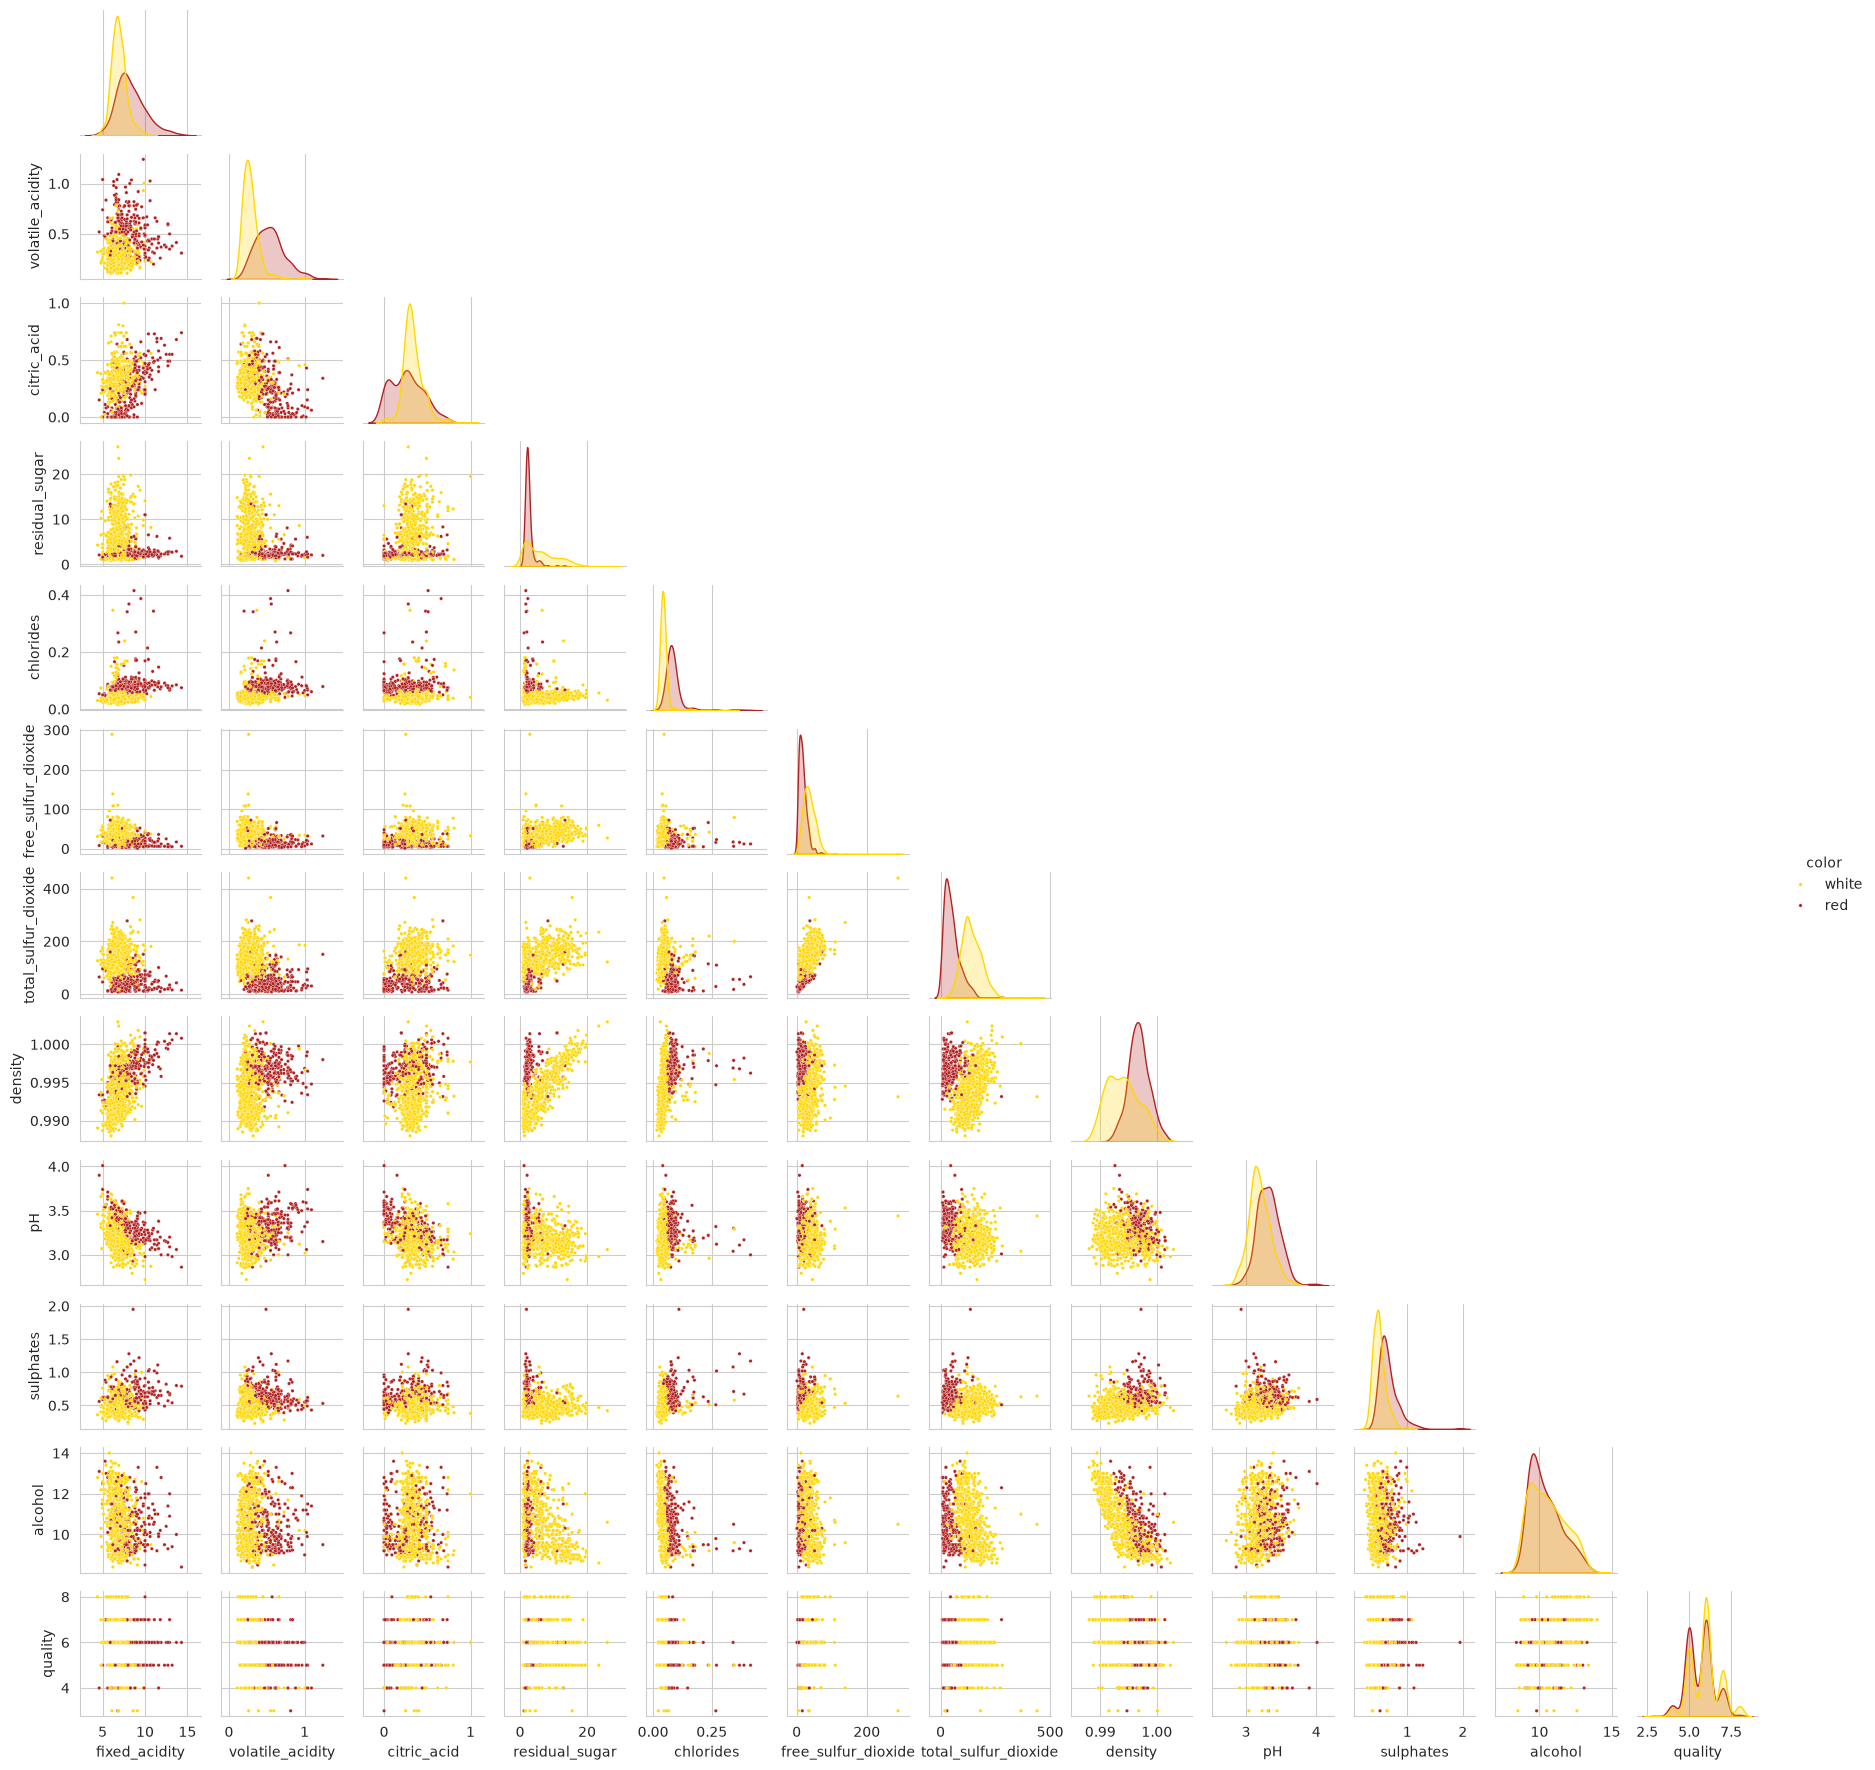

In [3]:
# все 6497 точек на графике сливаются, поэтому беру 1000 случайных
pair_sample = data.sample(1000, random_state=42)
sns.pairplot(pair_sample, hue='color', palette={'red': 'firebrick', 'white': 'gold'}, corner=True, height=1.5,
             plot_kws={'s': 6}, diag_kws={'common_norm': False})
plt.show()

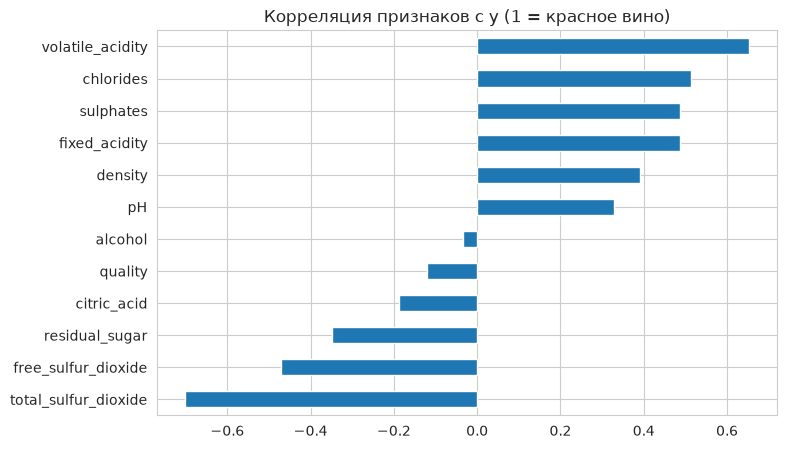

total_sulfur_dioxide   -0.700
free_sulfur_dioxide    -0.472
residual_sugar         -0.349
citric_acid            -0.187
quality                -0.119
alcohol                -0.033
pH                      0.329
density                 0.391
fixed_acidity           0.487
sulphates               0.487
chlorides               0.513
volatile_acidity        0.653
dtype: float64

In [4]:
fields = [c for c in data.columns if c != 'color']
correlations = data[fields].corrwith(y).sort_values()

correlations.plot(kind='barh', figsize=(8, 5), title='Корреляция признаков с y (1 = красное вино)')
plt.show()
correlations.round(3)

In [5]:
top2 = correlations.abs().sort_values(ascending=False).index[:2].tolist()
print('два поля с наибольшей |корреляцией|:', top2)

X = data[top2]
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X.describe().round(3)

два поля с наибольшей |корреляцией|: ['total_sulfur_dioxide', 'volatile_acidity']


,total_sulfur_dioxide,volatile_acidity
count,6497.000,6497.000
mean,0.253,0.173
std,0.130,0.110
min,0.000,0.000
25%,0.164,0.100
50%,0.258,0.140
75%,0.346,0.213
max,1.000,1.000


**Ответ.**

В данных 6497 вин: 1599 красных (около 25%) и 4898 белых. Все признаки числовые, кроме `color`.

По парному графику видно, что красные и белые вина сильнее всего отличаются по сере (`total_sulfur_dioxide`, `free_sulfur_dioxide`), у белых ее намного больше. Еще у красных выше `volatile_acidity` и `chlorides`. По `alcohol` и `quality` разницы почти нет.

Самая большая по модулю корреляция с `y` у `total_sulfur_dioxide` (-0.70) и `volatile_acidity` (0.65), их и беру в `X`. После MinMaxScaler оба признака от 0 до 1, результат снова перевожу в DataFrame с теми же названиями столбцов.

## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn. 

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

accuracy на всех данных: 0.9546
accuracy на кросс-валидации: 0.9551
доля белых вин: 0.7539


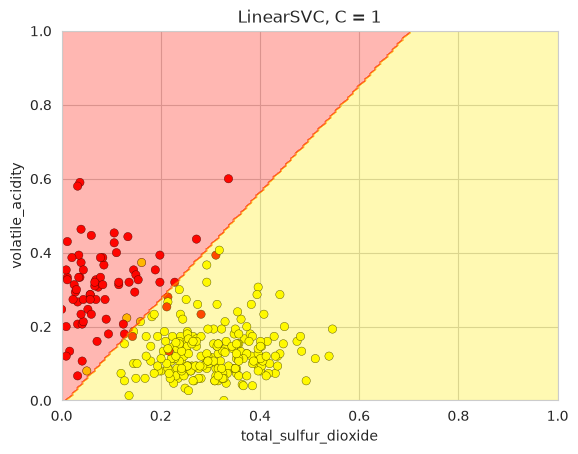

In [6]:
LSVC = LinearSVC()
LSVC.fit(X, y)
print('accuracy на всех данных:', round(LSVC.score(X, y), 4))
print('accuracy на кросс-валидации:', round(cross_val_score(LinearSVC(), X, y, cv=cv5).mean(), 4))
print('доля белых вин:', round(1 - y.mean(), 4))

X_color = X.sample(300, random_state=45)
y_color = y.loc[X_color.index]
y_color = y_color.map(lambda r: 'red' if r == 1 else 'yellow')

ax = plt.axes()
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolors='k', linewidths=0.3)

# -----------
x_axis, y_axis = np.arange(0, 1.005, .005), np.arange(0, 1.005, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel], index=X.columns).T   # имена столбцов как у X, иначе sklearn ругается
y_grid_predictions = LSVC.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
# -----------
ax.set(xlabel=X.columns[0], ylabel=X.columns[1], xlim=(0, 1), ylim=(0, 1), title='LinearSVC, C = 1')
plt.show()

C = 0.001  веса: [[-0.9  0.6]]  b: [-0.4]
C = 0.01  веса: [[-3.   2.4]]  b: [-0.2]
C = 1  веса: [[-7.5  5.2]]  b: [0.1]
C = 100  веса: [[-7.8  5.4]]  b: [0.1]


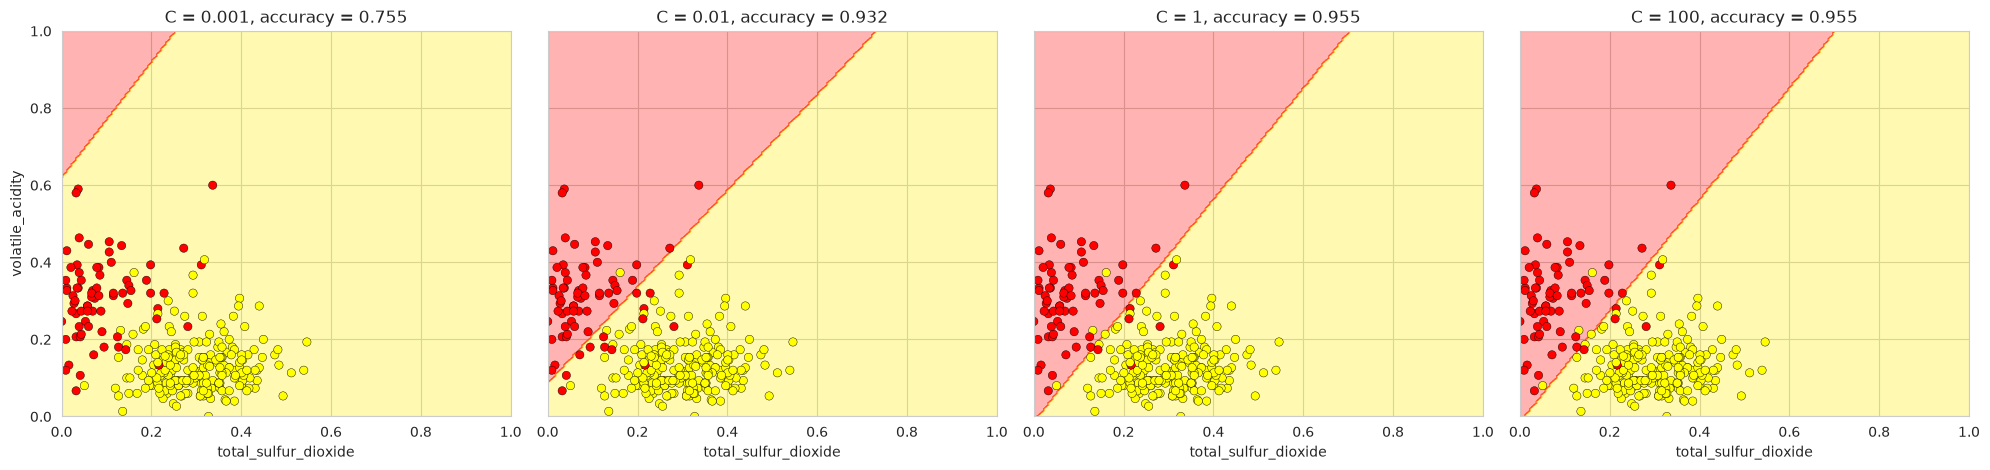

In [7]:
# пробую разные C
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for ax, C in zip(axes, [0.001, 0.01, 1, 100]):
    model = LinearSVC(C=C, max_iter=10000).fit(X, y)
    pred = model.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, pred, cmap=plt.cm.autumn_r, alpha=.3, vmin=0, vmax=1)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolors='k', linewidths=0.3)
    ax.set(title=f'C = {C}, accuracy = {model.score(X, y):.3f}', xlabel=X.columns[0], xlim=(0, 1), ylim=(0, 1))
    print('C =', C, ' веса:', model.coef_.round(1), ' b:', model.intercept_.round(1))
axes[0].set_ylabel(X.columns[1])
plt.tight_layout()
plt.show()

**Ответ.**

LinearSVC только по двум признакам угадывает цвет примерно в 95.5% случаев, на кросс-валидации столько же. Если всегда отвечать "белое", было бы 75.4%, так что модель работает. Граница получается прямой линией: красные вина в левом верхнем углу (мало серы и высокая кислотность). Ошибки в основном возле границы, где точки двух классов перемешаны, и прямой их не разделить.

С разными C:
- C = 0.001 - веса очень маленькие, почти все вина предсказываются белыми, accuracy 0.755, как у константы (недообучение);
- C = 0.01 - уже 0.932;
- C = 1 и C = 100 - 0.955, веса почти одинаковые.

Чем больше C, тем слабее регуляризация и тем сильнее модель подстраивается под обучающие данные. Но после C = 1 почти ничего не меняется.

## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

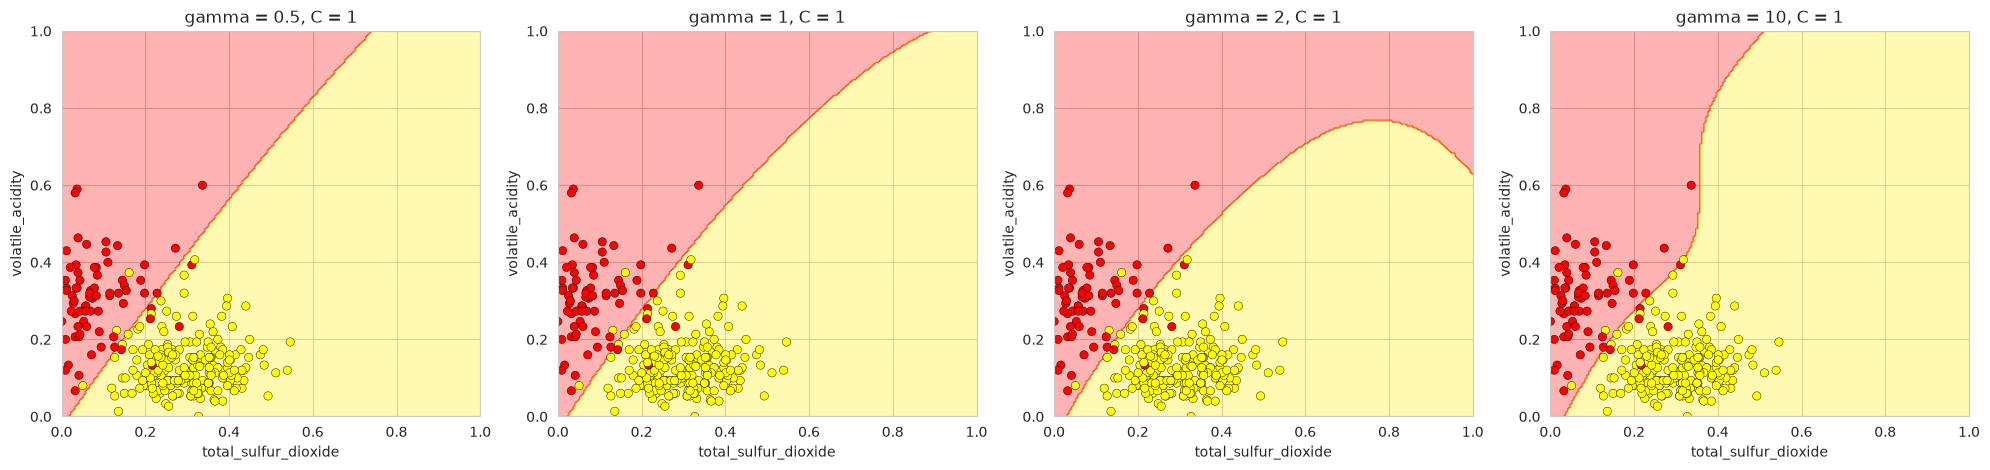

,train,CV,опорных векторов
0.5,0.9554,0.9552,1067.0
1.0,0.9547,0.9544,955.0
2.0,0.9547,0.9551,877.0
10.0,0.9551,0.9551,775.0


In [8]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None):
    # 1. обучаем модель
    estimator.fit(X, y)
    # 2. 300 случайных записей и их цвета
    X_color = X.sample(300, random_state=45)
    y_color = y.loc[X_color.index].map(lambda r: 'red' if r == 1 else 'yellow')
    # 3. сетка, прогноз на сетке, заливка
    x_axis, y_axis = np.arange(0, 1.005, .005), np.arange(0, 1.005, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()], index=X.columns).T
    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)
    if ax is None:
        ax = plt.axes()
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3, vmin=0, vmax=1)
    # 4. точки сверху
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolors='k', linewidths=0.3)
    ax.set(xlabel=X.columns[0], ylabel=X.columns[1], xlim=(0, 1), ylim=(0, 1), title=title)
    return ax


gammas = [.5, 1, 2, 10]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
res = {}
for ax, gamma in zip(axes, gammas):
    SVC_Gaussian = SVC(kernel='rbf', gamma=gamma)
    plot_decision_boundary(SVC_Gaussian, X, y, ax=ax, title=f'gamma = {gamma}, C = 1')
    res[gamma] = {'train': SVC_Gaussian.score(X, y),
                  'CV': cross_val_score(SVC(kernel='rbf', gamma=gamma), X, y, cv=cv5).mean(),
                  'опорных векторов': SVC_Gaussian.n_support_.sum()}
plt.tight_layout()
plt.show()
pd.DataFrame(res).T.round(4)

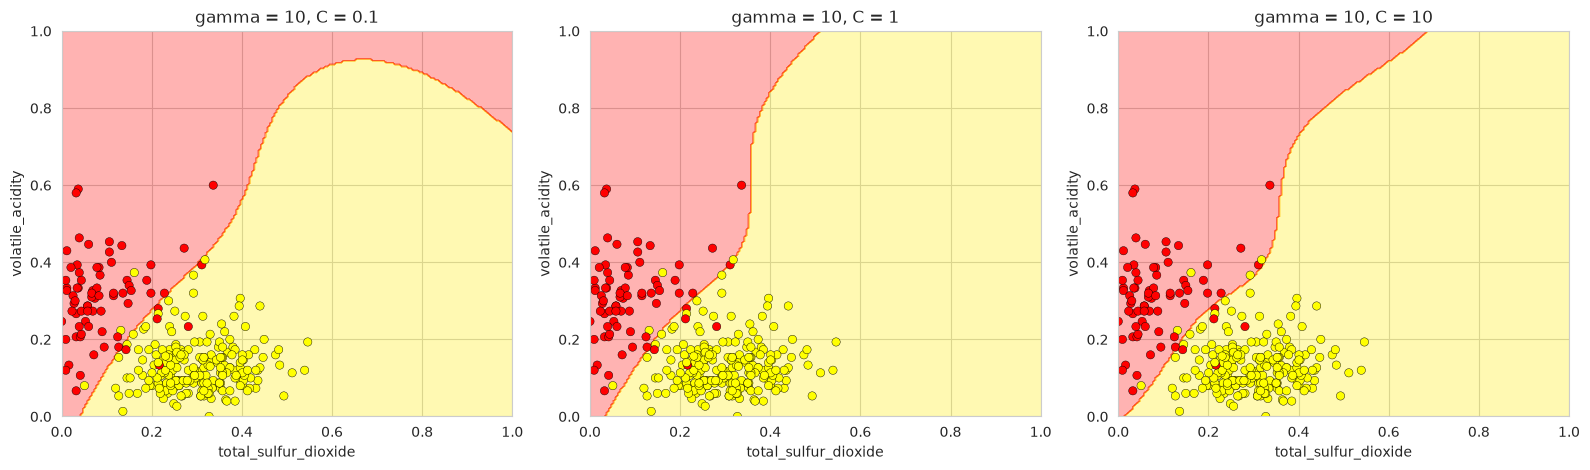

,train,CV,опорных векторов
0.1,0.9543,0.9551,968.0
1.0,0.9551,0.9551,775.0
10.0,0.9554,0.9561,735.0


In [9]:
Cs = [.1, 1, 10]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
res = {}
for ax, C in zip(axes, Cs):
    SVC_Gaussian = SVC(kernel='rbf', gamma=10, C=C)
    plot_decision_boundary(SVC_Gaussian, X, y, ax=ax, title=f'gamma = 10, C = {C}')
    res[C] = {'train': SVC_Gaussian.score(X, y),
              'CV': cross_val_score(SVC(kernel='rbf', gamma=10, C=C), X, y, cv=cv5).mean(),
              'опорных векторов': SVC_Gaussian.n_support_.sum()}
plt.tight_layout()
plt.show()
pd.DataFrame(res).T.round(4)

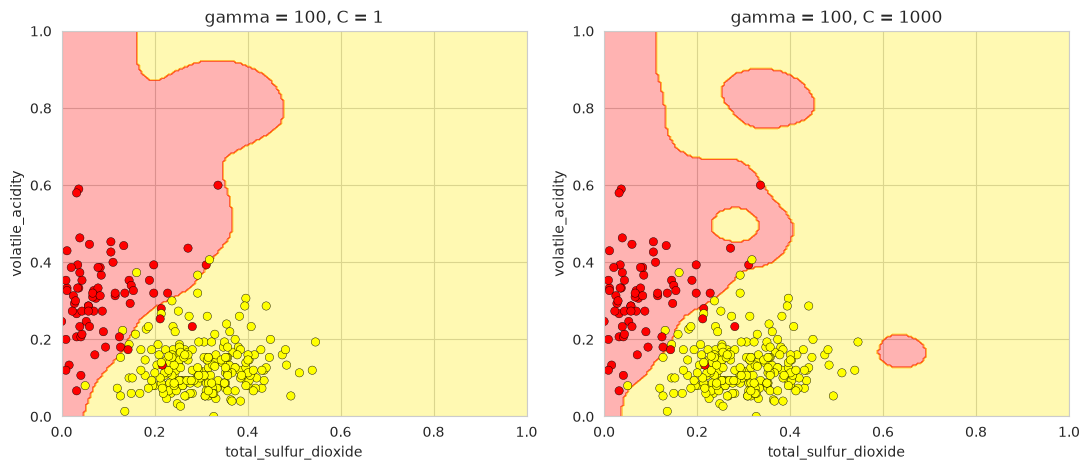

,train,CV
"gamma = 100, C = 1",0.9563,0.9541
"gamma = 100, C = 1000",0.9575,0.9538


In [10]:
# еще попробую совсем большие gamma и C
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
res = {}
for ax, (gamma, C) in zip(axes, [(100, 1), (100, 1000)]):
    model = SVC(kernel='rbf', gamma=gamma, C=C)
    plot_decision_boundary(model, X, y, ax=ax, title=f'gamma = {gamma}, C = {C}')
    res[f'gamma = {gamma}, C = {C}'] = {'train': model.score(X, y),
                                         'CV': cross_val_score(SVC(kernel='rbf', gamma=gamma, C=C), X, y, cv=cv5).mean()}
plt.tight_layout()
plt.show()
pd.DataFrame(res).T.round(4)

**Ответ.**

gamma отвечает за ширину гауссова ядра. При gamma = 0.5 граница почти прямая, как у LinearSVC. Чем больше gamma, тем сильнее она изгибается, а при gamma = 10 уже огибает облако красных вин.

При этом accuracy почти не меняется, на кросс-валидации везде около 0.955. Классы на этих двух признаках частично перекрываются, и как ни изгибай границу, эти точки правильно не разделить. Меняется число опорных векторов: 1067 при gamma = 0.5 и 775 при gamma = 10.

C при gamma = 10 на точность тоже почти не влияет (0.955-0.956), но с ростом C опорных векторов становится меньше (968, 775, 735), и граница точнее обходит отдельные точки.

При gamma = 100 и C = 1000 уже видно переобучение: появляются маленькие "острова" вокруг отдельных точек. Accuracy на train выросла до 0.9575, а на кросс-валидации наоборот упала до 0.954.

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [11]:
data = pd.read_csv(filepath)
y = (data['color'] == 'red').astype(int)
X = data[data.columns[:-1]]
# признаки в разных масштабах, для rbf лучше привести их к [0, 1]
X = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)

kwargs = {'kernel': 'rbf'}
svc = SVC(**kwargs)
nystroem = Nystroem(random_state=42, **kwargs)
sgd = SGDClassifier(random_state=42)
print(X.shape)

(6497, 12)


In [12]:
%%timeit -r 5 -n 1 -o
svc.fit(X, y)

56 ms ± 568 μs per loop (mean ± std. dev. of 5 runs, 1 loop each)


<TimeitResult : 56 ms ± 568 μs per loop (mean ± std. dev. of 5 runs, 1 loop each)>

In [13]:
t_svc = _

In [14]:
%%timeit -r 5 -n 1 -o
X_transformed = nystroem.fit_transform(X)
sgd.fit(X_transformed, y)

42.2 ms ± 8.48 ms per loop (mean ± std. dev. of 5 runs, 1 loop each)


<TimeitResult : 42.2 ms ± 8.48 ms per loop (mean ± std. dev. of 5 runs, 1 loop each)>

In [15]:
t_nys = _

In [16]:
X2 = pd.concat([X] * 5, ignore_index=True)
y2 = pd.concat([y] * 5, ignore_index=True)

print(X2.shape)
print(y2.shape)

(32485, 12)
(32485,)


In [17]:
t_svc2 = %timeit -r 3 -n 1 -o svc.fit(X2, y2)
t_nys2 = %timeit -r 3 -n 1 -o sgd.fit(nystroem.fit_transform(X2), y2)

763 ms ± 28.6 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


163 ms ± 1.13 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [18]:
timing = pd.DataFrame({'SVC': [t_svc.average, t_svc2.average],
                       'Nystroem + SGD': [t_nys.average, t_nys2.average]},
                      index=['исходные данные', 'данные x5'])
timing.round(3)

,SVC,Nystroem + SGD
исходные данные,0.056,0.042
данные x5,0.763,0.163


In [19]:
# заодно сравню точность на тестовой выборке
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print('SVC:', round(SVC(kernel='rbf').fit(X_tr, y_tr).score(X_te, y_te), 4))
nys = Nystroem(kernel='rbf', random_state=42).fit(X_tr)
sgd_test = SGDClassifier(random_state=42).fit(nys.transform(X_tr), y_tr)
print('Nystroem + SGD:', round(sgd_test.score(nys.transform(X_te), y_te), 4))

SVC: 0.9964
Nystroem + SGD: 0.9862


**Ответ.**

Здесь используются все признаки (включая `quality`), перед обучением они масштабированы MinMaxScaler.

На исходных данных (6497 строк) разница небольшая: SVC обучается примерно за 56 мс, Nystroem + SGD за 42 мс. Данных мало, и по всем признакам классы разделяются легко. После увеличения данных в 5 раз SVC стал обучаться примерно в 14 раз дольше (0.76 с), а Nystroem + SGD всего в 4 раза (0.16 с). Время Nystroem + SGD растет примерно линейно с числом строк, а SVC быстрее, потому что ему нужна матрица ядра размером n x n. На еще больших данных разница была бы заметнее.

Но Nystroem + SGD немного проигрывает по точности: на тестовой выборке 0.986 против 0.996 у SVC, потому что ядро тут только приближается.